In [2]:
import sys

sys.path.append("..")

import pandas as pd
from src.data_collection import get_stock_prices

In [5]:
ticker = ["MSFT", "AAPL", "JPM", "JNJ", "XOM", "WMT"]

stock_data = {t: get_stock_prices(t, max_records=1250) for t in ticker}

In [6]:
for ticker in stock_data:

    stock_data[ticker]["date"] = pd.to_datetime(
        stock_data[ticker]["date"]
    )

    stock_data[ticker] = (
        stock_data[ticker]
        .sort_values("date")
        .reset_index(drop=True)
    )

    stock_data[ticker]["daily_return"] = (
        stock_data[ticker]["close"].pct_change()
    )

In [7]:
returns = pd.DataFrame()

for ticker, df in stock_data.items():
    returns[ticker] = df.set_index("date")["daily_return"]

returns.shape

(1250, 6)

In [8]:
returns.isnull().sum()

MSFT    1
AAPL    1
JPM     1
JNJ     1
XOM     1
WMT     1
dtype: int64

In [9]:
returns = returns.dropna()

returns.describe()

,MSFT,AAPL,JPM,JNJ,XOM,WMT
count,1249.000000,1249.000000,1249.000000,1249.000000,1249.000000,1249.000000
mean,0.000592,0.000842,0.000684,0.000481,0.000925,0.000787
std,0.017763,0.017680,0.015393,0.011131,0.016781,0.014181
min,-0.099931,-0.092456,-0.080502,-0.075917,-0.078853,-0.113758
25%,-0.008466,-0.007756,-0.007244,-0.005452,-0.008712,-0.006382
50%,0.000473,0.001124,0.001163,0.000393,0.001262,0.001080
75%,0.010125,0.009720,0.009031,0.006564,0.011223,0.008219
max,0.155067,0.153288,0.115445,0.061932,0.064113,0.095488


In [10]:
cumulative_returns = (1 + returns).cumprod()

IMPLEMENT AUTOMATICALY TO RUN EVERY DAY AND SEE IF THE DATA IS OK, IF NOT DO SOMETHING

In [11]:
for ticker, df in stock_data.items():
    print(ticker, "duplicate rows:", df.duplicated().sum())

MSFT duplicate rows: 0
AAPL duplicate rows: 0
JPM duplicate rows: 0
JNJ duplicate rows: 0
XOM duplicate rows: 0
WMT duplicate rows: 0


In [12]:
for ticker, df in stock_data.items():

    invalid_high_open = (df["high"] < df["open"]).sum()
    invalid_high_close = (df["high"] < df["close"]).sum()
    invalid_low_open = (df["low"] > df["open"]).sum()
    invalid_low_close = (df["low"] > df["close"]).sum()

    print(f"\n{ticker}")
    print("High < Open:", invalid_high_open)
    print("High < Close:", invalid_high_close)
    print("Low > Open:", invalid_low_open)
    print("Low > Close:", invalid_low_close)


MSFT
High < Open: 0
High < Close: 0
Low > Open: 0
Low > Close: 0

AAPL
High < Open: 0
High < Close: 0
Low > Open: 0
Low > Close: 0

JPM
High < Open: 1
High < Close: 0
Low > Open: 0
Low > Close: 0

JNJ
High < Open: 0
High < Close: 0
Low > Open: 1
Low > Close: 0

XOM
High < Open: 1
High < Close: 0
Low > Open: 0
Low > Close: 0

WMT
High < Open: 0
High < Close: 0
Low > Open: 1
Low > Close: 0


In [13]:
for ticker, df in stock_data.items():

    print(
        ticker,
        "negative prices:",
        (df[["open", "high", "low", "close"]] < 0).sum().sum()
    )

    print(
        ticker,
        "negative volume:",
        (df["volume"] < 0).sum()
    )

MSFT negative prices: 0
MSFT negative volume: 0
AAPL negative prices: 0
AAPL negative volume: 0
JPM negative prices: 0
JPM negative volume: 0
JNJ negative prices: 0
JNJ negative volume: 0
XOM negative prices: 0
XOM negative volume: 0
WMT negative prices: 0
WMT negative volume: 0


In [14]:
for ticker, df in stock_data.items():

    is_sorted = df["date"].is_monotonic_increasing

    print(ticker, "chronological:", is_sorted)

MSFT chronological: True
AAPL chronological: True
JPM chronological: True
JNJ chronological: True
XOM chronological: True
WMT chronological: True


VISUALIZATION

In [15]:
import matplotlib.pyplot as plt

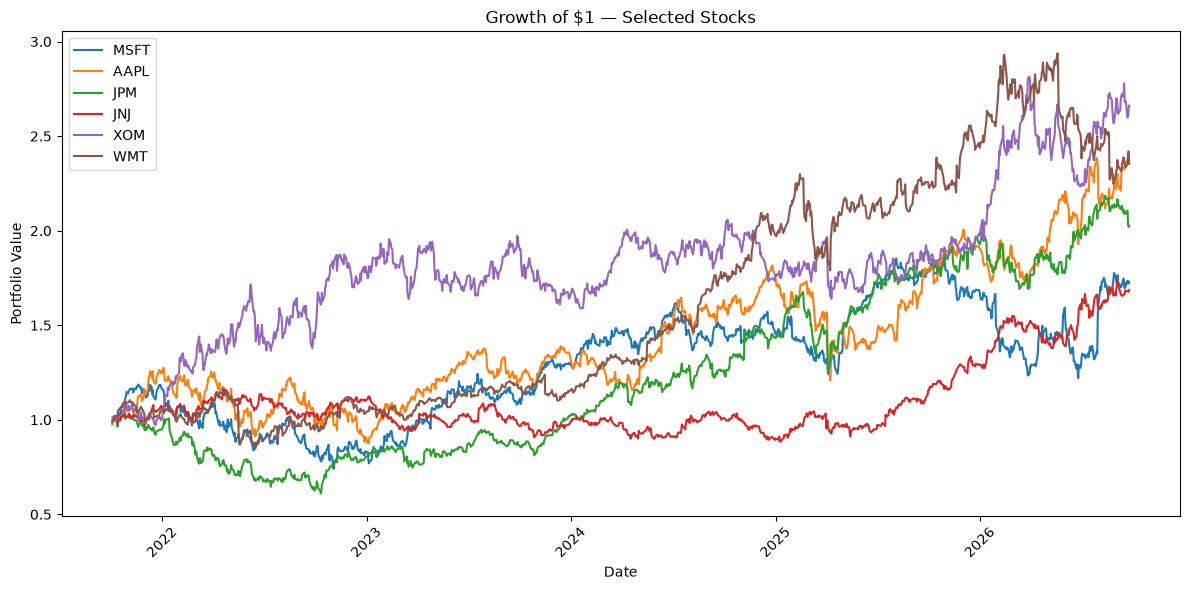

In [16]:
plt.figure(figsize=(12, 6))

for ticker in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[ticker],
        label=ticker
    )

plt.title("Growth of $1 — Selected Stocks")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

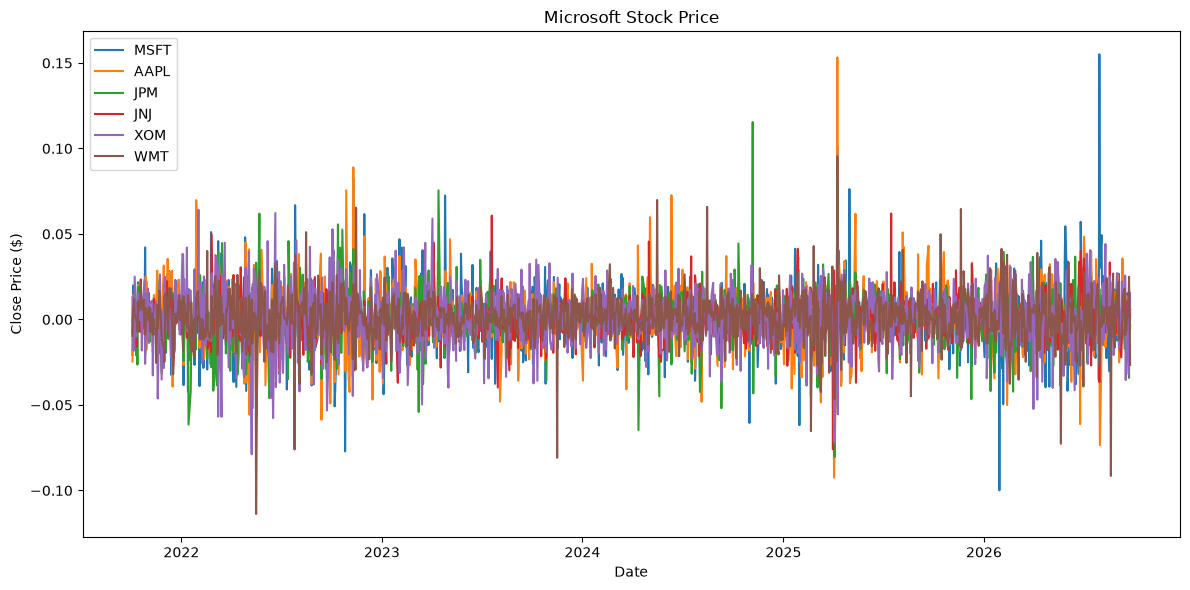

In [17]:
plt.figure(figsize=(12, 6))

for ticker in returns.columns:
    plt.plot(
        returns.index,
        returns[ticker],
        label=ticker
    )

plt.xlabel('Date')
plt.ylabel('Close Price ($)')
plt.title('Microsoft Stock Price')

# plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()

In [18]:
performance = pd.DataFrame({
    "Annualized Return": returns.mean() * 252,
    "Annualized Volatility": returns.std() * (252 ** 0.5)
})

performance['Cumulative Return'] = cumulative_returns.iloc[-1] - 1

performance


,Annualized Return,Annualized Volatility,Cumulative Return
MSFT,0.149203,0.281973,0.722345
AAPL,0.212061,0.280655,1.354855
JPM,0.172281,0.244349,1.025728
JNJ,0.121091,0.176692,0.686795
XOM,0.233090,0.266395,1.661086
WMT,0.198370,0.225114,1.355128


In [19]:
performance_display = performance.copy()

performance_display[
    ["Annualized Return", "Annualized Volatility", "Cumulative Return"]
] *= 100

performance_display = performance_display.round(2)

performance_display = performance_display.astype(str) + "%"

performance_display

,Annualized Return,Annualized Volatility,Cumulative Return
MSFT,14.92%,28.2%,72.23%
AAPL,21.21%,28.07%,135.49%
JPM,17.23%,24.43%,102.57%
JNJ,12.11%,17.67%,68.68%
XOM,23.31%,26.64%,166.11%
WMT,19.84%,22.51%,135.51%


In [20]:
performance["Sharpe Ratio of 0% risk-free rate"] = (
    performance["Annualized Return"] /
    performance["Annualized Volatility"]
)

performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate
MSFT,0.149,0.282,0.722,0.529
AAPL,0.212,0.281,1.355,0.756
JPM,0.172,0.244,1.026,0.705
JNJ,0.121,0.177,0.687,0.685
XOM,0.233,0.266,1.661,0.875
WMT,0.198,0.225,1.355,0.881


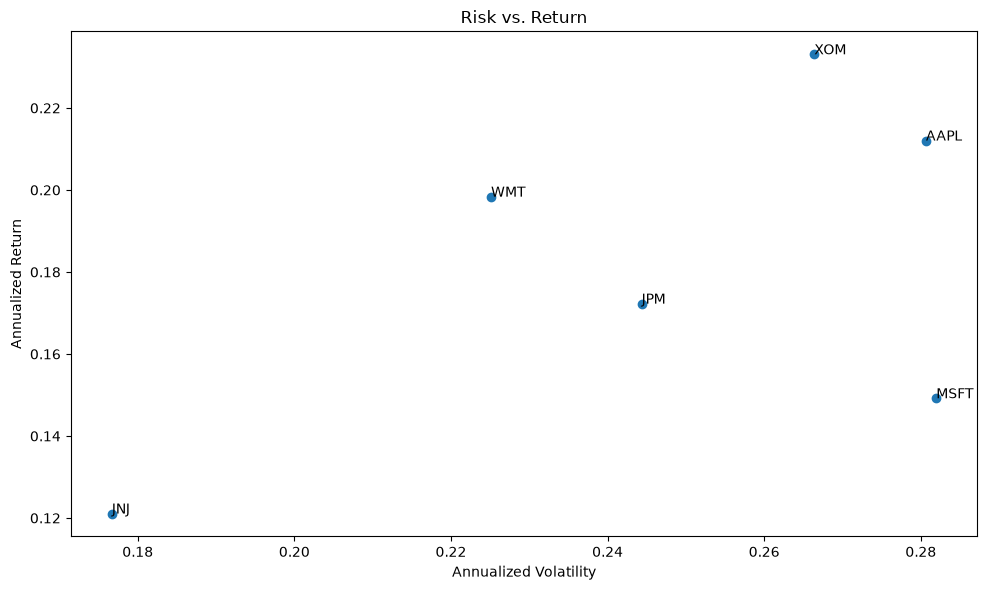

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    performance["Annualized Volatility"],
    performance["Annualized Return"]
)

for ticker in performance.index:
    plt.annotate(
        ticker,
        (
            performance.loc[ticker, "Annualized Volatility"],
            performance.loc[ticker, "Annualized Return"]
        )
    )

plt.title("Risk vs. Return")
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")

plt.tight_layout()
plt.show()

In [22]:
running_max = cumulative_returns.cummax()

drawdown = (
    cumulative_returns - running_max
) / running_max

max_drawdown = drawdown.min()

performance["Maximum Drawdown"] = max_drawdown

performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown
MSFT,0.149,0.282,0.722,0.529,-0.376
AAPL,0.212,0.281,1.355,0.756,-0.334
JPM,0.172,0.244,1.026,0.705,-0.406
JNJ,0.121,0.177,0.687,0.685,-0.236
XOM,0.233,0.266,1.661,0.875,-0.207
WMT,0.198,0.225,1.355,0.881,-0.260


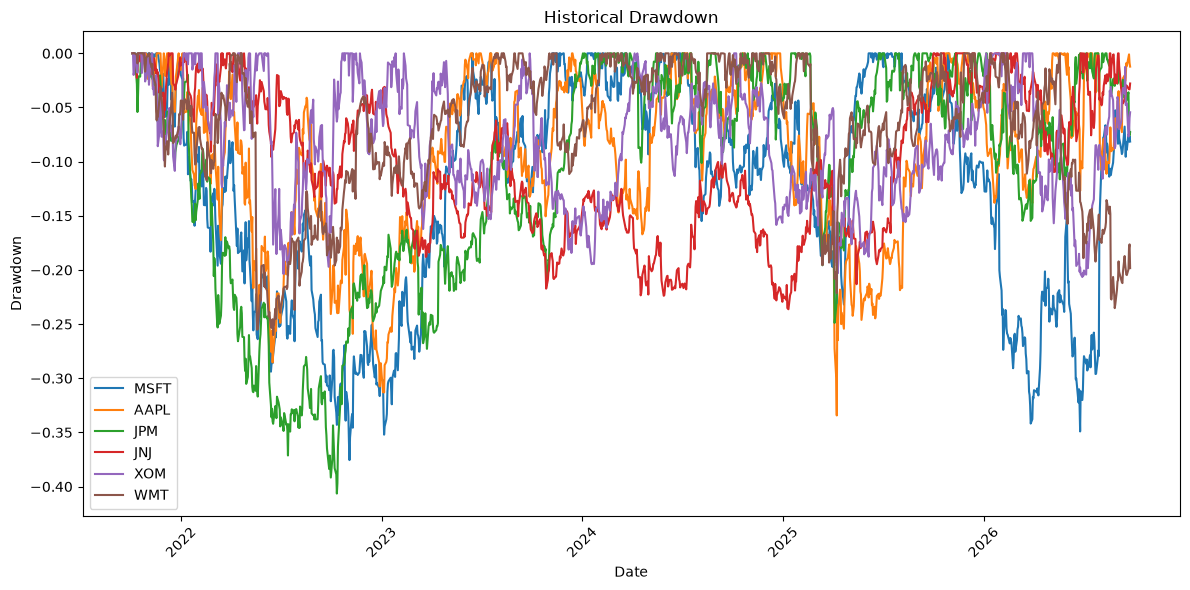

In [23]:
plt.figure(figsize=(12, 6))

for ticker in drawdown.columns:
    plt.plot(
        drawdown.index,
        drawdown[ticker],
        label=ticker
    )

plt.title("Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [24]:
start_date = returns.index.min()
end_date = returns.index.max()

years = (end_date - start_date).days / 365.25


In [25]:
cagr = (
    cumulative_returns.iloc[-1] ** (1 / years)
) - 1

performance["CAGR"] = cagr
performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown,CAGR
MSFT,0.149,0.282,0.722,0.529,-0.376,0.116
AAPL,0.212,0.281,1.355,0.756,-0.334,0.188
JPM,0.172,0.244,1.026,0.705,-0.406,0.153
JNJ,0.121,0.177,0.687,0.685,-0.236,0.111
XOM,0.233,0.266,1.661,0.875,-0.207,0.218
WMT,0.198,0.225,1.355,0.881,-0.260,0.188


In [26]:
var_95 = returns.quantile(0.05)

performance["VaR 95%"] = var_95
performance.round(3)

,Annualized Return,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown,CAGR,VaR 95%
MSFT,0.149,0.282,0.722,0.529,-0.376,0.116,-0.027
AAPL,0.212,0.281,1.355,0.756,-0.334,0.188,-0.027
JPM,0.172,0.244,1.026,0.705,-0.406,0.153,-0.024
JNJ,0.121,0.177,0.687,0.685,-0.236,0.111,-0.017
XOM,0.233,0.266,1.661,0.875,-0.207,0.218,-0.028
WMT,0.198,0.225,1.355,0.881,-0.260,0.188,-0.019


In [27]:
metrics = performance.copy()

metrics = metrics[
    [
        "Annualized Return",
        "CAGR",
        "Annualized Volatility",
        "Cumulative Return",
        "Sharpe Ratio of 0% risk-free rate",
        "Maximum Drawdown",
        "VaR 95%"
    ]
]

metrics

,Annualized Return,CAGR,Annualized Volatility,Cumulative Return,Sharpe Ratio of 0% risk-free rate,Maximum Drawdown,VaR 95%
MSFT,0.149203,0.115554,0.281973,0.722345,0.529141,-0.375565,-0.026961
AAPL,0.212061,0.187990,0.280655,1.354855,0.755594,-0.334337,-0.027198
JPM,0.172281,0.152557,0.244349,1.025728,0.705060,-0.406450,-0.024245
JNJ,0.121091,0.110884,0.176692,0.686795,0.685323,-0.236278,-0.017039
XOM,0.233090,0.217564,0.266395,1.661086,0.874978,-0.206508,-0.027568
WMT,0.198370,0.188018,0.225114,1.355128,0.881197,-0.260086,-0.019451


In [43]:
import importlib
import src.database

importlib.reload(src.database)

<module 'src.database' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\database.py'>

In [41]:
from src.database import insert_stock_data

In [42]:
insert_stock_data(stock_data["MSFT"])

In [36]:
for ticker, df in stock_data.items():
    print(f"Loading {ticker}...")
    insert_stock_data(df)

Loading MSFT...
Loading AAPL...
Loading JPM...
Loading JNJ...
Loading XOM...
Loading WMT...


In [44]:
from src.database import get_latest_date

In [45]:
latest = get_latest_date("MSFT")

print(latest)

2026-09-24


In [47]:
import importlib
import src.data_collection

importlib.reload(src.data_collection)

<module 'src.data_collection' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\data_collection.py'>

In [49]:
from src.data_collection import get_stock_prices

In [52]:
latest_date = get_latest_date("MSFT")

new_data = get_stock_prices(
    "MSFT",
    max_records=1250,
    start_date=latest_date
)

print("Latest date in database:", latest_date)
print("New records:", len(new_data))

Latest date in database: 2026-09-24
New records: 0


In [53]:
import importlib
import src.update_pipeline

importlib.reload(src.update_pipeline)

<module 'src.update_pipeline' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\update_pipeline.py'>

In [54]:
from src.update_pipeline import update_stock

In [56]:
tickers = [
    "MSFT",
    "AAPL",
    "JPM",
    "JNJ",
    "XOM",
    "WMT"
]

for ticker in tickers:
    update_stock(ticker)

MSFT: latest date in database = 2026-09-24
MSFT: no new data.
AAPL: latest date in database = 2026-09-24
AAPL: no new data.
JPM: latest date in database = 2026-09-24
JPM: no new data.
JNJ: latest date in database = 2026-09-24
JNJ: no new data.
XOM: latest date in database = 2026-09-24
XOM: no new data.
WMT: latest date in database = 2026-09-24
WMT: no new data.


In [62]:
import importlib
import src.data_collection

importlib.reload(src.data_collection)

<module 'src.data_collection' from 'c:\\Financial_project\\stock-market-analysis\\notebooks\\..\\src\\data_collection.py'>

In [63]:
from src.data_collection import get_stock_prices

In [ ]:
ticker = ["MSFT", "AAPL", "JPM", "JNJ", "XOM", "WMT"]

stock_data1 = {t: get_stock_prices(t, start_date=get_latest_date(t)) for t in ticker}